In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/SolarPrediction.csv")
df = df.rename(columns={"WindDirection(Degrees)": "WindDirection", "Speed": "WindSpeed"})
df.head()

,UNIXTime,Data,Time,Radiation,Temperature,Pressure,Humidity,WindDirection,WindSpeed,TimeSunRise,TimeSunSet
0,1475229326,9/29/2016 12:00:00 AM,23:55:26,1.21,48,30.46,59,177.39,5.62,06:13:00,18:13:00
1,1475229023,9/29/2016 12:00:00 AM,23:50:23,1.21,48,30.46,58,176.78,3.37,06:13:00,18:13:00
2,1475228726,9/29/2016 12:00:00 AM,23:45:26,1.23,48,30.46,57,158.75,3.37,06:13:00,18:13:00
3,1475228421,9/29/2016 12:00:00 AM,23:40:21,1.21,48,30.46,60,137.71,3.37,06:13:00,18:13:00
4,1475228124,9/29/2016 12:00:00 AM,23:35:24,1.17,48,30.46,62,104.95,5.62,06:13:00,18:13:00


In [2]:
date_part = df["Data"].str.split().str[0]

df["Datetime"] = pd.to_datetime(date_part + " " + df["Time"], format="%m/%d/%Y %H:%M:%S")
df["Sunrise"]  = pd.to_datetime(date_part + " " + df["TimeSunRise"], format="%m/%d/%Y %H:%M:%S")
df["Sunset"]   = pd.to_datetime(date_part + " " + df["TimeSunSet"], format="%m/%d/%Y %H:%M:%S")

df = df.sort_values("Datetime").reset_index(drop=True)
df["Date"] = df["Datetime"].dt.date
df["Hour"] = df["Datetime"].dt.hour

In [3]:
print(df["Datetime"].min(), "->", df["Datetime"].max())
print(df["Date"].nunique(), "days")
print(df.isna().sum().sum(), "missing,", df.duplicated().sum(), "duplicates")
df[["Radiation","Temperature","Pressure","Humidity","WindDirection","WindSpeed"]].describe()

2016-09-01 00:00:08 -> 2016-12-31 23:55:01
118 days
0 missing, 0 duplicates


,Radiation,Temperature,Pressure,Humidity,WindDirection,WindSpeed
count,32686.000000,32686.000000,32686.000000,32686.000000,32686.000000,32686.000000
mean,207.124697,51.103255,30.422879,75.016307,143.489821,6.243869
std,315.916387,6.201157,0.054673,25.990219,83.167500,3.490474
min,1.110000,34.000000,30.190000,8.000000,0.090000,0.000000
25%,1.230000,46.000000,30.400000,56.000000,82.227500,3.370000
50%,2.660000,50.000000,30.430000,85.000000,147.700000,5.620000
75%,354.235000,55.000000,30.460000,97.000000,179.310000,7.870000
max,1601.260000,71.000000,30.560000,103.000000,359.950000,40.500000


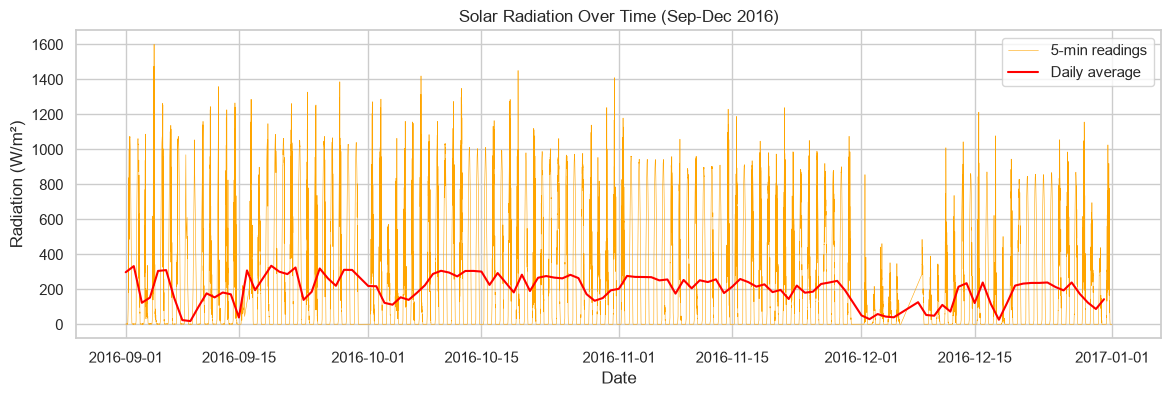

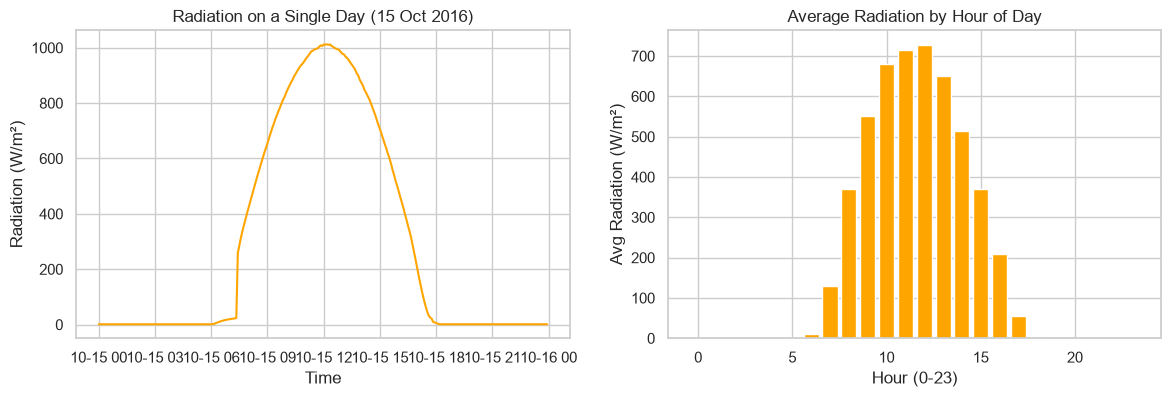

In [4]:
import os
os.makedirs("../plots", exist_ok=True)
sns.set_theme(style="whitegrid")

# Plot 1: whole period
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df["Datetime"], df["Radiation"], linewidth=0.4, color="orange", label="5-min readings")
daily_mean = df.groupby("Date")["Radiation"].mean()
ax.plot(pd.to_datetime(daily_mean.index), daily_mean.values, color="red", linewidth=1.5, label="Daily average")
ax.set_title("Solar Radiation Over Time (Sep-Dec 2016)")
ax.set_xlabel("Date"); ax.set_ylabel("Radiation (W/m²)"); ax.legend()
plt.savefig("../plots/01_radiation_over_time.png", dpi=150, bbox_inches="tight")
plt.show()

# Plot 2: one day, and average by hour
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
one_day = df[df["Date"] == pd.to_datetime("2016-10-15").date()]
axes[0].plot(one_day["Datetime"], one_day["Radiation"], color="orange")
axes[0].set_title("Radiation on a Single Day (15 Oct 2016)")
axes[0].set_xlabel("Time"); axes[0].set_ylabel("Radiation (W/m²)")
hourly = df.groupby("Hour")["Radiation"].mean()
axes[1].bar(hourly.index, hourly.values, color="orange")
axes[1].set_title("Average Radiation by Hour of Day")
axes[1].set_xlabel("Hour (0-23)"); axes[1].set_ylabel("Avg Radiation (W/m²)")
plt.savefig("../plots/02_radiation_by_hour.png", dpi=150, bbox_inches="tight")
plt.show()

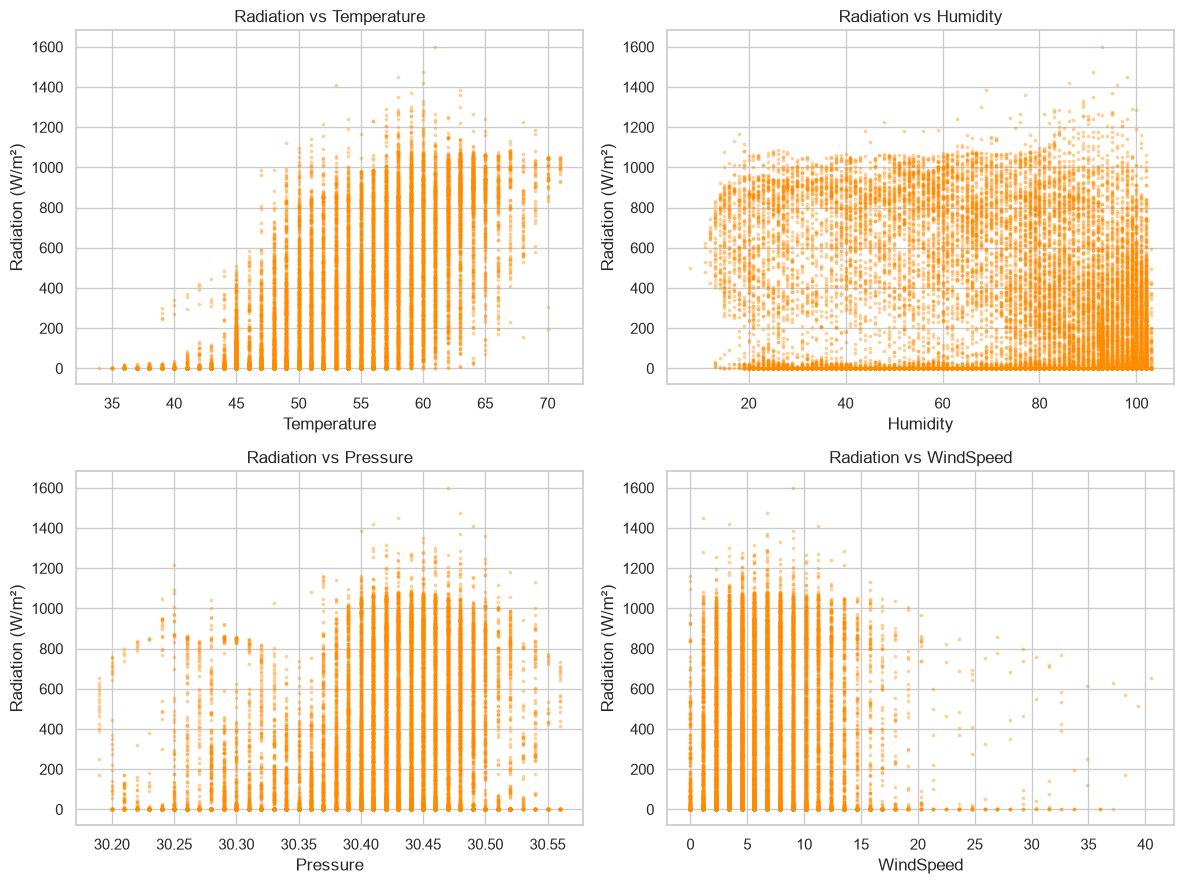

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, col in zip(axes.flat, ["Temperature", "Humidity", "Pressure", "WindSpeed"]):
    ax.scatter(df[col], df["Radiation"], s=3, alpha=0.3, color="darkorange")
    ax.set_xlabel(col); ax.set_ylabel("Radiation (W/m²)")
    ax.set_title(f"Radiation vs {col}")
plt.tight_layout()
plt.savefig("../plots/03_radiation_vs_parameters.png", dpi=150, bbox_inches="tight")
plt.show()

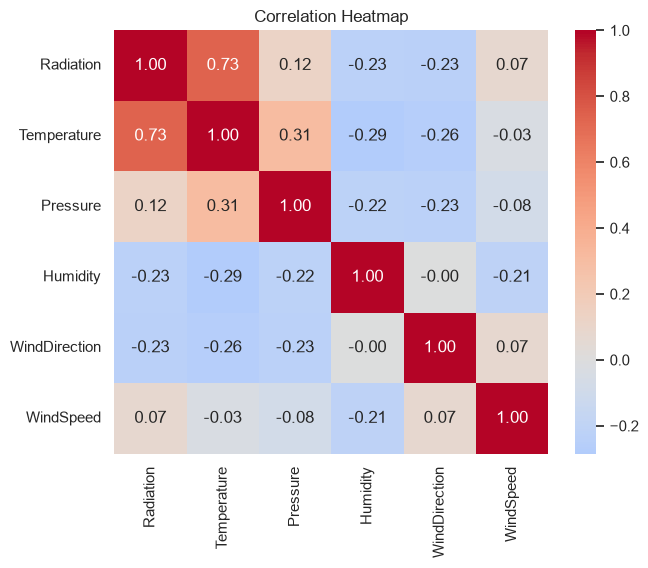

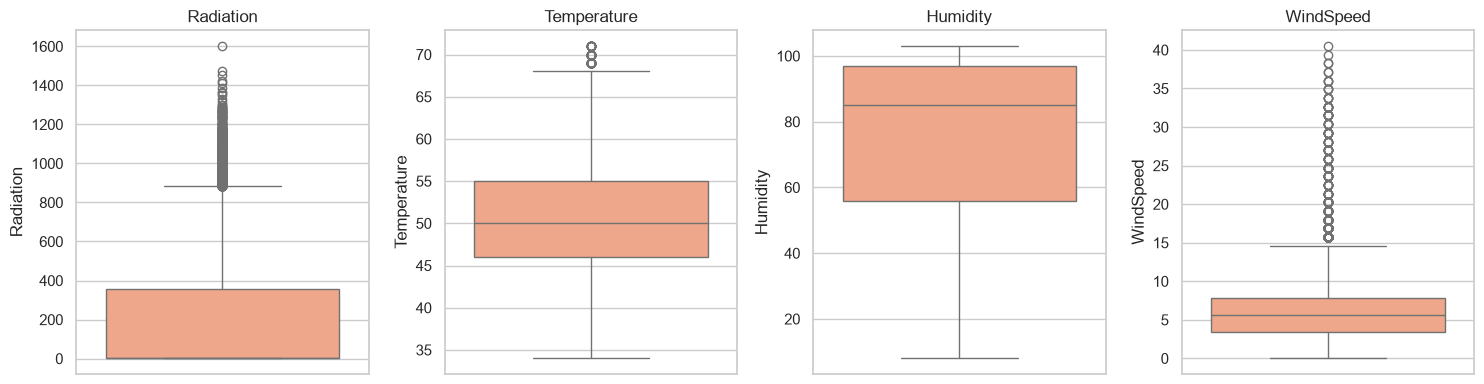

In [6]:
features = ["Radiation", "Temperature", "Pressure", "Humidity", "WindDirection", "WindSpeed"]

plt.figure(figsize=(7, 5.5))
sns.heatmap(df[features].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.savefig("../plots/04_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, col in zip(axes, ["Radiation", "Temperature", "Humidity", "WindSpeed"]):
    sns.boxplot(y=df[col], ax=ax, color="lightsalmon")
    ax.set_title(col)
plt.tight_layout()
plt.savefig("../plots/05_boxplots_outliers.png", dpi=150, bbox_inches="tight")
plt.show()

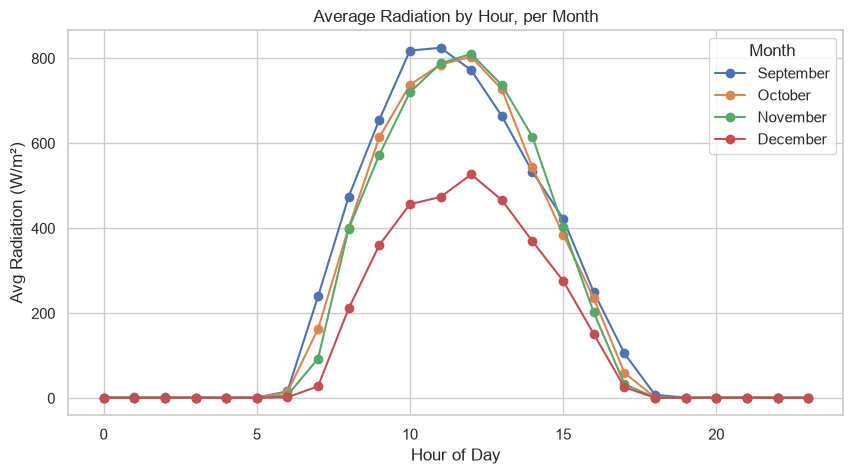

In [7]:
df["Month"] = df["Datetime"].dt.month_name()
order = ["September", "October", "November", "December"]
monthly_hour = df.pivot_table(index="Hour", columns="Month", values="Radiation", aggfunc="mean")[order]
monthly_hour.plot(figsize=(10, 5), marker="o")
plt.title("Average Radiation by Hour, per Month")
plt.xlabel("Hour of Day"); plt.ylabel("Avg Radiation (W/m²)")
plt.savefig("../plots/06_bonus_monthly_hourly.png", dpi=150, bbox_inches="tight")
plt.show()